# Name : Manthan Madankar
# Class : C2-B2
# Roll no : 16
# ML Practical 2

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn import metrics

In [2]:
df=pd.read_csv('USA_Housing.csv')
df.head()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price,Address
0,79545.458574,5.682861,7.009188,4.09,23086.800503,1.059034e+06,"208 Michael Ferry Apt. 674\nLaurabury, NE 3701..."
1,79248.642455,6.002900,6.730821,3.09,40173.072174,1.505891e+06,"188 Johnson Views Suite 079\nLake Kathleen, CA..."
2,61287.067179,5.865890,8.512727,5.13,36882.159400,1.058988e+06,"9127 Elizabeth Stravenue\nDanieltown, WI 06482..."
3,63345.240046,7.188236,5.586729,3.26,34310.242831,1.260617e+06,USS Barnett\nFPO AP 44820
4,59982.197226,5.040555,7.839388,4.23,26354.109472,6.309435e+05,USNS Raymond\nFPO AE 09386


In [3]:
df.tail()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price,Address
4995,60567.944140,7.830362,6.137356,3.46,22837.361035,1.060194e+06,USNS Williams\nFPO AP 30153-7653
4996,78491.275435,6.999135,6.576763,4.02,25616.115489,1.482618e+06,"PSC 9258, Box 8489\nAPO AA 42991-3352"
4997,63390.686886,7.250591,4.805081,2.13,33266.145490,1.030730e+06,"4215 Tracy Garden Suite 076\nJoshualand, VA 01..."
4998,68001.331235,5.534388,7.130144,5.44,42625.620156,1.198657e+06,USS Wallace\nFPO AE 73316
4999,65510.581804,5.992305,6.792336,4.07,46501.283803,1.298950e+06,"37778 George Ridges Apt. 509\nEast Holly, NV 2..."


In [4]:
df.shape

(5000, 7)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 7 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Avg. Area Income              5000 non-null   float64
 1   Avg. Area House Age           5000 non-null   float64
 2   Avg. Area Number of Rooms     5000 non-null   float64
 3   Avg. Area Number of Bedrooms  5000 non-null   float64
 4   Area Population               5000 non-null   float64
 5   Price                         5000 non-null   float64
 6   Address                       5000 non-null   object 
dtypes: float64(6), object(1)
memory usage: 273.6+ KB


In [6]:
df.describe()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5.000000e+03
mean,68583.108984,5.977222,6.987792,3.981330,36163.516039,1.232073e+06
std,10657.991214,0.991456,1.005833,1.234137,9925.650114,3.531176e+05
min,17796.631190,2.644304,3.236194,2.000000,172.610686,1.593866e+04
25%,61480.562388,5.322283,6.299250,3.140000,29403.928702,9.975771e+05
50%,68804.286404,5.970429,7.002902,4.050000,36199.406689,1.232669e+06
75%,75783.338666,6.650808,7.665871,4.490000,42861.290769,1.471210e+06
max,107701.748378,9.519088,10.759588,6.500000,69621.713378,2.469066e+06


In [7]:
df.isnull().sum()

Avg. Area Income                0
Avg. Area House Age             0
Avg. Area Number of Rooms       0
Avg. Area Number of Bedrooms    0
Area Population                 0
Price                           0
Address                         0
dtype: int64

In [8]:
pd.set_option('display.float_format','{:.2f}'.format)

In [9]:
df.head()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price,Address
0,79545.46,5.68,7.01,4.09,23086.80,1059033.56,"208 Michael Ferry Apt. 674\nLaurabury, NE 3701..."
1,79248.64,6.00,6.73,3.09,40173.07,1505890.91,"188 Johnson Views Suite 079\nLake Kathleen, CA..."
2,61287.07,5.87,8.51,5.13,36882.16,1058987.99,"9127 Elizabeth Stravenue\nDanieltown, WI 06482..."
3,63345.24,7.19,5.59,3.26,34310.24,1260616.81,USS Barnett\nFPO AP 44820
4,59982.20,5.04,7.84,4.23,26354.11,630943.49,USNS Raymond\nFPO AE 09386


In [10]:
df.drop("Address",axis=1,inplace=True)

In [11]:
df.head()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price
0,79545.46,5.68,7.01,4.09,23086.80,1059033.56
1,79248.64,6.00,6.73,3.09,40173.07,1505890.91
2,61287.07,5.87,8.51,5.13,36882.16,1058987.99
3,63345.24,7.19,5.59,3.26,34310.24,1260616.81
4,59982.20,5.04,7.84,4.23,26354.11,630943.49


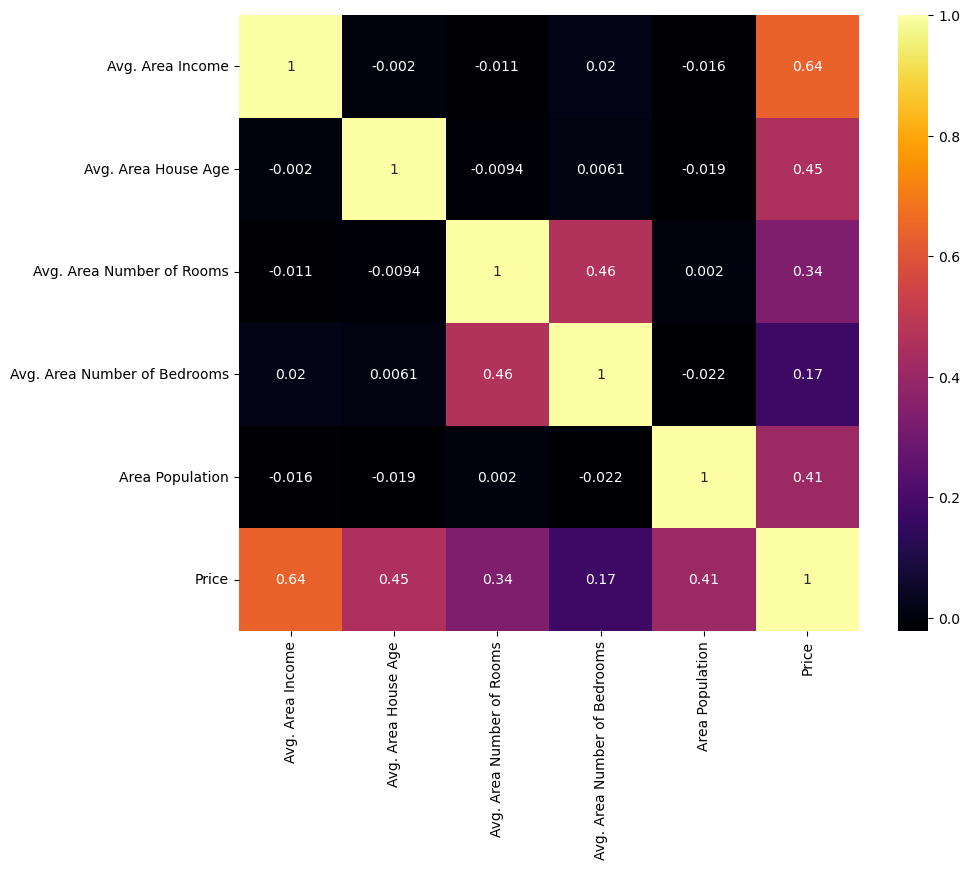

In [12]:
plt.figure(figsize=(10,8))
numeric_df=df.select_dtypes(include=['number'])
sns.heatmap(numeric_df.corr(),annot=True,cmap='inferno')
plt.show()

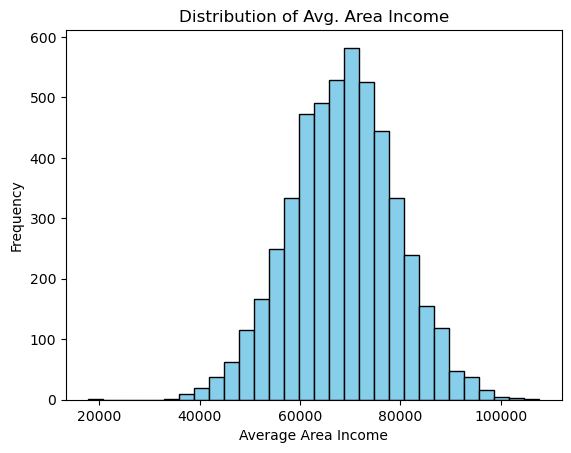

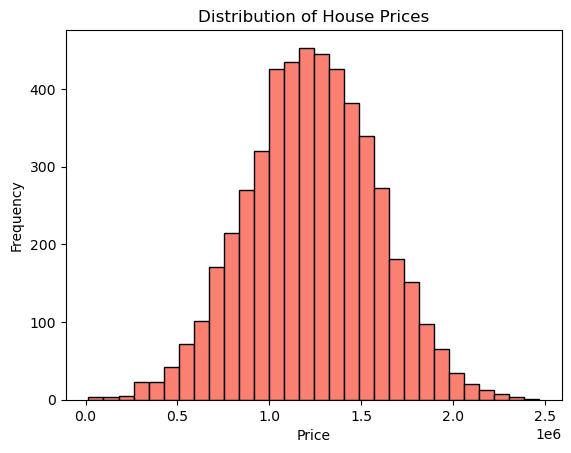

In [13]:
plt.hist(df["Avg. Area Income"],bins=30, color="skyblue", edgecolor="black")
plt.xlabel("Average Area Income")
plt.ylabel("Frequency")
plt.title("Distribution of Avg. Area Income")
plt.show()

plt.hist(df["Price"],bins=30, color="salmon", edgecolor="black")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.title("Distribution of House Prices")
plt.show()


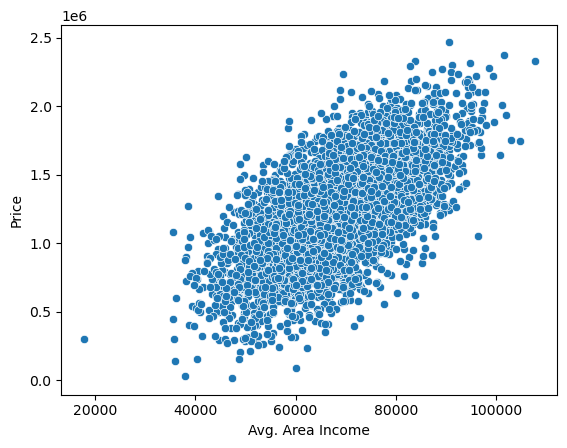

In [14]:
sns.scatterplot(x=df["Avg. Area Income"],y=df['Price'])
plt.show()

In [15]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [21]:
X = df[['Avg. Area Income']]
y = df['Price']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
slr_model = LinearRegression()
slr_model.fit(X_train, y_train)
y_pred = slr_model.predict(X_test)
print("Simple Linear Regression model result")
print('----------------------------------------')
print('MAE:', mean_absolute_error(y_test, y_pred))
print('MSE:', mean_squared_error(y_test, y_pred))
print('RMSE:', np.sqrt(mean_squared_error(y_test, y_pred)))
print('R2 score:', r2_score(y_test, y_pred))

Simple Linear Regression model result
----------------------------------------
MAE: 216826.3530998906
MSE: 74194887058.66
RMSE: 272387.38417676394
R2 score: 0.39694865192619766


In [17]:
print('Intercept:',slr_model.intercept_)
print('Slope:',slr_model.coef_[0])

Intercept: -225053.70287170215
Slope: 21.208906292657524


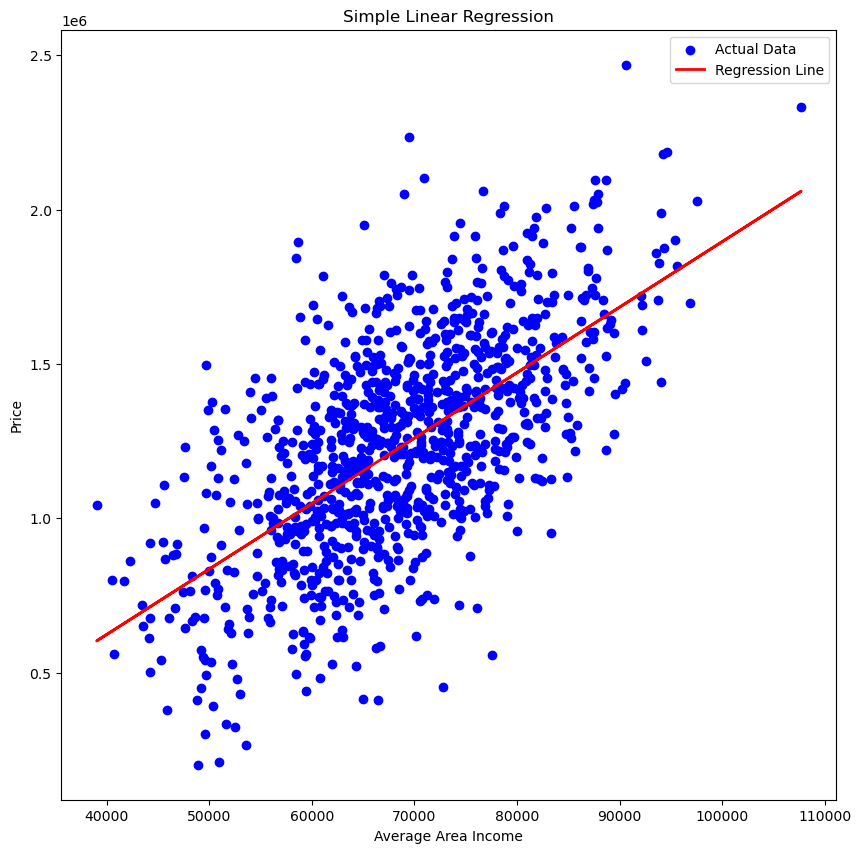

In [18]:
plt.figure(figsize=(10,10))
plt.scatter(X_test,y_test,color='blue',label='Actual Data')
plt.plot(X_test,y_pred,color='red',linewidth=2,label='Regression Line')
plt.xlabel('Average Area Income')
plt.ylabel('Price')
plt.title("Simple Linear Regression")
plt.legend()
plt.show()

In [19]:
income=float(input("Enter avg area income:"))
new_data=np.array([[income]])
prediction=slr_model.predict(new_data)
print('Predicted house price:${:,.2f}'.format(prediction[0]))

Enter avg area income: 48946


Predicted house price:$813,037.42


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


# Multiple Linear Regression

In [39]:
X = df.drop('Price', axis=1)
y = df['Price']  
X_train,X_test,y_train,y_test=train_test_split(
    X,y,test_size=0.2,random_state=42
)

In [40]:
mlr=LinearRegression()
mlr.fit(X_train,y_train)
coef = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': mlr.coef_
})

In [41]:
y_pred = mlr.predict(X_test)
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R²:", r2_score(y_test, y_pred))

MAE: 80879.09723487172
MSE: 10089009300.890953
RMSE: 100444.0605555697
R²: 0.9179971706834579


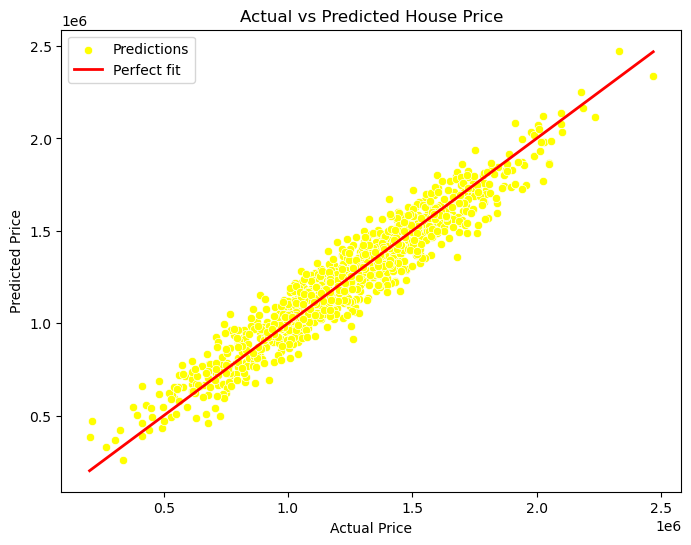

In [52]:
predictions=mlr.predict(X_test)
plt.figure(figsize=(8,6))
sns.scatterplot(x=y_test, y=y_pred, color='yellow', label='Predictions')
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], 
         color='red', linewidth=2, label='Perfect fit')
plt.title('Actual vs Predicted House Price')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.legend()
plt.show()

In [55]:
income = float(input('Enter avg area income: '))
house_age = float(input('Enter avg area house age: '))
rooms = float(input('Enter avg area no of rooms: '))
bedrooms = float(input('Enter avg area no of bedrooms: '))
population = float(input("Enter area population: "))
test_input = np.array([[income, house_age, rooms, bedrooms, population]])
predicted_price = mlr.predict(test_input)
print("Predicted House Price = ${:,.2f}".format(predicted_price[0]))

Enter avg area income:  454966
Enter avg area house age:  30
Enter avg area no of rooms:  5
Enter avg area no of bedrooms:  7
Enter area population:  3265


Predicted House Price = $12,820,999.25


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [22]:
from sklearn.model_selection import GridSearchCV

In [23]:
from sklearn.linear_model import Ridge
ridge=Ridge()
ridge.fit(X_train,y_train)
ridge_pred=ridge.predict(X_test)
print("Default Ridge R^2:",r2_score(y_test,ridge_pred))

Default Ridge R^2: 0.3969486519262033


In [30]:
param_grid = {'alpha': [0.001, 0.01, 0.1, 1, 10, 100]}
grid_ridge = GridSearchCV(estimator=Ridge(), param_grid=param_grid, scoring='r2', cv=5)
grid_ridge.fit(X_train, y_train)
print("Best alpha:", grid_ridge.best_params_)
print("Best CV R^2:", grid_ridge.best_score_)
best_ridge = grid_ridge.best_estimator_
ridge_pred = best_ridge.predict(X_test)
print('MAE:', mean_absolute_error(y_test, ridge_pred))
print('MSE:', mean_squared_error(y_test, ridge_pred))
print('RMSE:', np.sqrt(mean_squared_error(y_test, ridge_pred)))
print('Test R^2:', r2_score(y_test, ridge_pred))

Best alpha: {'alpha': 100}
Best CV R^2: 0.41110861933657433
MAE: 216826.35310007748
MSE: 74194887058.58913
RMSE: 272387.38417663384
Test R^2: 0.39694865192677375


# Lasso Regression

In [31]:
from sklearn.linear_model import Lasso
param_grid={'alpha':[0.001,0.01,0.1,1,10]}

In [32]:
grid_lasso=GridSearchCV(Lasso(max_iter=5000),param_grid,cv=5,scoring='r2')
grid_lasso.fit(X_train,y_train)

GridSearchCV(cv=5, estimator=Lasso(max_iter=5000),
             param_grid={'alpha': [0.001, 0.01, 0.1, 1, 10]}, scoring='r2')

In [33]:
print(grid_lasso.best_params_)

{'alpha': 10}


In [35]:
lasso_pred=grid_lasso.predict(X_test)
print(r2_score(y_test,lasso_pred))

0.39694865193706386


In [36]:
print('MAE:', mean_absolute_error(y_test,lasso_pred))
print('MSE:', mean_squared_error(y_test, lasso_pred))
print('RMSE:', np.sqrt(mean_squared_error(y_test,lasso_pred)))
print('Test R^2:', r2_score(y_test, lasso_pred))

MAE: 216826.35310341447
MSE: 74194887057.3231
RMSE: 272387.3841743099
Test R^2: 0.39694865193706386
